# Part 5:  Vibe-Coding Emerging Optimizers on CIFAR Classification 

As large language models (LLMs) reshape software engineering, we are entering a new era of AI-assisted programming where human creativity and machine execution merge. Instead of focusing on every low-level implementation detail, developers can prioritize **ideas, exploration, and iteration speed**, while the model handles much of the routine coding. This is the essence of [**vibe coding**](https://en.wikipedia.org/wiki/Vibe_coding?utm_source=chatgpt.com): coding by “vibes” and letting AI accelerate the path from concept to working system. In this homework, you will practice vibe coding by using AI assistants such as [ChatGPT](https://chat.openai.com), [Gemini](https://gemini.google.com/app), or [Claude](https://www.anthropic.com/claude-code) to help design and implement optimizers for CIFAR image classification.  

---

## 1. What is *Vibe Coding*? 

**Vibe coding** is a paradigm popularized by Andrej Karpathy in 2025. It emphasizes generating most of the code through LLMs while the human programmer acts as a **guide, tester, and refiner**. Instead of carefully reviewing every line, you iterate based on execution results, keeping the creative process at the center.  

Karpathy put it simply:  
> *“Fully giving in to the vibes, embracing exponentials, and forgetting that the code even exists.”*  

**Learn more :**
- [IBM: What is Vibe Coding?](https://www.ibm.com/think/topics/vibe-coding?utm_source=chatgpt.com)  
- [Replit Blog: What is Vibe Coding?](https://blog.replit.com/what-is-vibe-coding?utm_source=chatgpt.com)  

---

## 2. Objectives 

- Understand and implement **novel optimizers** (Muon, Scion, SODA).  
- Practice **vibe coding** as a workflow with LLMs.  
- Compare optimizer performance on **CIFAR-10** across Transformer and ResNet architectures.  
- Analyze results critically and reflect on the coding process.  

---

## 3. Task Overview 

You will implement and compare four optimizers on **CIFAR-10 classification** with two architectures: a **Transformer**  and a **ResNet** .  

- **Optimizers**: Muon , Scion , SODA , Adam (baseline)  
- **Models**: Transformer, ResNet  
- **Comparison metrics**: convergence speed, final test accuracy , training stability  

---

## 4. Optimizers to Implement 

### (1) Muon 
Muon applies **Newton–Schulz orthonormalization** to gradient updates of 2D weight matrices, making them invariant to input conditioning.  
References:  
- [Muon Blog (Keller Jordan)](https://kellerjordan.github.io/posts/muon/?utm_source=chatgpt.com)  
- [Deriving Muon (Jeremy Bernstein)](https://jeremybernste.in/writing/deriving-muon?utm_source=chatgpt.com)  
- [Muon GitHub Repo](https://github.com/KellerJordan/Muon?utm_source=chatgpt.com)  
- [Convergence Bound (arXiv)](https://arxiv.org/abs/2507.01598?utm_source=chatgpt.com)  

---

### (2) Scion 
Scion constrains updates differently for hidden vs input/output layers, using **spectral norm** for hidden layers and **ℓ∞ norm** for others. This improves stability and hyperparameter transfer.  
References:  
- [Scion Paper](https://arxiv.org/abs/2502.07529)  
- [Scion Official Code](https://github.com/LIONS-EPFL/scion)  

---

### (3) SODA 
SODA wraps a base optimizer with a theoretically grounded, initialization-centered **1/k weight-decay schedule**, motivating us to test whether it improves CIFAR-10 training without tuning weight decay.  
References:  
- [SODA Paper (arXiv)](https://arxiv.org/pdf/2605.11172)  
- [SODA GitHub Repo](https://github.com/tmpethick/soda_code)  

---

### (4) Adam 
Adam is the standard baseline optimizer combining momentum and adaptive learning rates. Use either `Adam` or `AdamW` from PyTorch.

---

## 5. Steps & Deliverables 

1. **Model Implementation (5 pts)**  
   - Build a Transformer for CIFAR classification.  
   - Build a ResNet (ResNet-18 or similar).  

2. **Optimizer Integration (8 pts)**  
   - Implement Muon, Scion, SODA optimizers using your AI assistant in a form which is compatible with `torch.optim.Optimizer`.  
   - Use Adam as baseline.  

3. **Training & Evaluation (7 pts)**  
   - Train both models with all optimizers.  
   - Collect metrics: training loss, validation accuracy, time-to-accuracy.  
   - Present results with plots and a summary table.  

4. **Discussion & Reflection (5 pts)**  
   - Compare optimizers in terms of convergence speed, stability, and accuracy.  
   - Reflect on your experience using **vibe coding** with AI assistants.  
   - What worked well? What challenges did you face?  

---

Good luck and enjoy vibe-coding your way through optimizers!!


## Setup

In [14]:
# Install dependencies if needed:
# %pip install torch torchvision matplotlib numpy

import torch
from torch import nn
from torch.utils.data import DataLoader
import torchvision
import numpy as np
import matplotlib.pyplot as plt


In [15]:
# Configuration (extra cell, listed in USAGE_NOTES.md section 8).
# Every experiment setting is defined here and used by the cells below.
import copy
import json
import math
import os
import random
import time

# SMOKE_TEST = True trains every (model, optimizer) pair for a few batches only. It checks the
# whole pipeline (data, models, optimizers, training, plots) and measures the time per batch.
# Set it to False for the learning-rate sweep and the final runs.
SMOKE_TEST = False

# Paths, relative to students/ (the notebook's working directory).
DATA_DIR = "./data"  # CIFAR-10 is downloaded here
# One metrics file per run. Smoke-test files go to a separate folder so that they are never
# mistaken for (or skipped in place of) real results.
RESULTS_DIR = "./results/smoke" if SMOKE_TEST else "./results"

# Device and precision: bf16 autocast on CUDA, plain fp32 on CPU. Weights and optimizer
# states always stay in fp32, so no gradient scaler is needed.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if DEVICE.type == "cuda" else None
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True  # faster convolutions (not bit-exact across runs)
    torch.set_float32_matmul_precision("high")  # TF32 for the remaining fp32 matmuls

# Data.
BATCH_SIZE = 512  # same for every run
VAL_SIZE = 5000  # training images held out as the validation set
SPLIT_SEED = 2026  # fixes the train/validation split for every run
NUM_WORKERS = 4

# Training budget, chosen after the GPU smoke test from the measured time per epoch (about
# 20-26 s per epoch and per (model, optimizer) on the RTX 3060 Laptop) and a total budget of
# about 4 hours: 20 epochs for the final runs, about a third of that for the sweep runs.
EPOCHS = 20  # final runs
SWEEP_EPOCHS = max(1, round(EPOCHS / 3))  # short learning-rate sweep runs
SWEEP_SEED = 0
FINAL_SEEDS = [0, 1]  # more seeds can be added later: finished runs are loaded from their files
RUN_FINAL_RUNS = True  # False: stop after the learning-rate sweep (to inspect it first)
WARMUP_FRACTION = 0.05  # linear LR warmup, used by AdamW only
# Untimed GPU warm-up before the first run that trains in a session (CUDA only, not in smoke
# mode): the laptop GPU slows down as it heats up, so timed runs should all start warm.
GPU_WARMUP_MINUTES = 10

# Smoke-test budget: a few batches per epoch, so that each run takes seconds on the GPU.
SMOKE_EPOCHS = 2
SMOKE_TRAIN_BATCHES = 3
SMOKE_EVAL_BATCHES = 2

os.makedirs(RESULTS_DIR, exist_ok=True)


def set_seed(seed):
    """Seed Python, NumPy and PyTorch (CPU and all CUDA devices)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


print(f"SMOKE_TEST={SMOKE_TEST}  device={DEVICE}  amp={AMP_DTYPE}  torch={torch.__version__}")
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

SMOKE_TEST=False  device=cuda  amp=torch.bfloat16  torch=2.14.1+cu130
GPU: NVIDIA GeForce RTX 3060 Laptop GPU


## Model implementation

In [16]:
# Prepare the CIFAR-10 datasets and data loaders (the same pipeline for every run).
# - Training set: the official training split minus VAL_SIZE held-out images, with the standard
#   augmentation (random crop with 4-pixel padding, horizontal flip).
# - Validation set: VAL_SIZE images held out from the official training split (stratified,
#   VAL_SIZE / 10 per class, fixed SPLIT_SEED), no augmentation. It is evaluated every epoch
#   and drives the learning-rate sweep and the time-to-accuracy.
# - Test set: the official test split, no augmentation. Evaluated only at the end of the
#   final runs (final test accuracy); never used for any choice.
import torchvision.transforms as T
from torch.utils.data import Subset

NUM_CLASSES = 10
EVAL_BATCH_SIZE = 1024
PIN_MEMORY = DEVICE.type == "cuda"

# Two views of the official training split: one gets the training augmentation, the other the
# plain evaluation transform (for the validation images). Transforms are attached below.
cifar_train_aug = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True)
cifar_train_plain = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=False)
cifar_test = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True)

# Stratified train/validation split, fixed by SPLIT_SEED.
_split_gen = torch.Generator().manual_seed(SPLIT_SEED)
_targets = torch.tensor(cifar_train_aug.targets)
train_idx, val_idx = [], []
for c in range(NUM_CLASSES):
    idx_c = torch.nonzero(_targets == c).flatten()
    idx_c = idx_c[torch.randperm(len(idx_c), generator=_split_gen)]
    val_idx += idx_c[: VAL_SIZE // NUM_CLASSES].tolist()
    train_idx += idx_c[VAL_SIZE // NUM_CLASSES :].tolist()
train_idx.sort()
val_idx.sort()


def channel_stats(images):
    """Exact per-channel mean and std of uint8 images (N, H, W, 3), scaled to [0, 1]."""
    levels = np.arange(256) / 255.0
    mean, std = [], []
    for c in range(images.shape[-1]):
        counts = np.bincount(images[..., c].ravel(), minlength=256)
        m = (counts * levels).sum() / counts.sum()
        mean.append(float(m))
        std.append(float(np.sqrt((counts * (levels - m) ** 2).sum() / counts.sum())))
    return tuple(mean), tuple(std)


# Normalization statistics from the training images only (validation images excluded).
CIFAR_MEAN, CIFAR_STD = channel_stats(cifar_train_aug.data[train_idx])

train_transform = T.Compose([
    T.RandomCrop(32, padding=4),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(CIFAR_MEAN, CIFAR_STD),
])
eval_transform = T.Compose([T.ToTensor(), T.Normalize(CIFAR_MEAN, CIFAR_STD)])
cifar_train_aug.transform = train_transform
cifar_train_plain.transform = eval_transform
cifar_test.transform = eval_transform

train_set = Subset(cifar_train_aug, train_idx)
val_set = Subset(cifar_train_plain, val_idx)
test_set = cifar_test


def make_loader(dataset, batch_size, shuffle, seed=None, drop_last=False):
    generator = torch.Generator().manual_seed(seed) if seed is not None else None
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        generator=generator,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
        persistent_workers=NUM_WORKERS > 0,
    )


def make_train_loader(seed):
    """Training loader for one run, built fresh for every run.

    The seeded generator fixes the shuffling and, with NUM_WORKERS > 0, the worker seeds that
    drive the random crops and flips (with NUM_WORKERS = 0 they come from the global RNG,
    seeded by set_seed at the start of the run). So for a given seed every optimizer sees
    exactly the same batches. The last incomplete batch is dropped, so every step uses
    BATCH_SIZE images.
    """
    return make_loader(train_set, BATCH_SIZE, shuffle=True, seed=seed, drop_last=True)


val_loader = make_loader(val_set, EVAL_BATCH_SIZE, shuffle=False)
test_loader = make_loader(test_set, EVAL_BATCH_SIZE, shuffle=False)
STEPS_PER_EPOCH = len(train_set) // BATCH_SIZE

print(f"train {len(train_set)}  val {len(val_set)}  test {len(test_set)}  "
      f"steps/epoch {STEPS_PER_EPOCH} (batch {BATCH_SIZE})")
print("mean", tuple(round(m, 4) for m in CIFAR_MEAN), " std", tuple(round(s, 4) for s in CIFAR_STD))

train 45000  val 5000  test 10000  steps/epoch 87 (batch 512)
mean (0.4912, 0.4822, 0.4466)  std (0.247, 0.2435, 0.2615)


In [17]:
import torch.nn.functional as F


class RMSNorm(nn.Module):
    """Parameter-free RMSNorm, as in Scion's DeiT setup (scion/examples/deit/main_scion.py)."""

    def forward(self, x):
        return F.rms_norm(x, (x.size(-1),))


class ScaledGELU(nn.Module):
    """sqrt(2) * GELU, to preserve the variance (Scion DeiT setup and README)."""

    def forward(self, x):
        return (2 ** 0.5) * F.gelu(x)


class Attention(nn.Module):
    """Multi-head self-attention with separate q, k, v projections (so that Muon and Scion
    treat Q, K and V as separate matrices, as recommended in Keller Jordan's Muon blog)."""

    def __init__(self, dim, num_heads):
        super().__init__()
        assert dim % num_heads == 0
        self.num_heads = num_heads
        self.q = nn.Linear(dim, dim)
        self.k = nn.Linear(dim, dim)
        self.v = nn.Linear(dim, dim)
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        B, N, C = x.shape
        q, k, v = (f(x).view(B, N, self.num_heads, C // self.num_heads).transpose(1, 2)
                   for f in (self.q, self.k, self.v))
        out = F.scaled_dot_product_attention(q, k, v)  # softmax(q k^T / sqrt(d_head)) v
        return self.proj(out.transpose(1, 2).reshape(B, N, C))


class TransformerBlock(nn.Module):
    """Pre-norm block: x + Attn(Norm(x)), then x + MLP(Norm(x))."""

    def __init__(self, dim, num_heads, mlp_ratio):
        super().__init__()
        self.norm1 = RMSNorm()
        self.attn = Attention(dim, num_heads)
        self.norm2 = RMSNorm()
        self.mlp = nn.Sequential(nn.Linear(dim, mlp_ratio * dim), ScaledGELU(), nn.Linear(mlp_ratio * dim, dim))

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        return x + self.mlp(self.norm2(x))


class CIFARTransformer(nn.Module):
    """Small Vision Transformer for 32x32 images.

    4x4 patches (64 tokens), width 256, depth 6, 8 heads (head dim 32), MLP hidden size 1024,
    learned positional embedding, no class token: the output is the mean over the tokens after
    a final RMSNorm. Pre-norm blocks with parameter-free RMSNorm and sqrt(2)*GELU (Scion's
    DeiT setup), the same architecture for every optimizer. About 4.76M parameters.

    Parameter roles, used by the shared grouping helper of the optimizers:
    `stem` (the patch embedding) is the input layer, `head` the output layer, `pos_embed` an
    embedding, the weights of the q, k, v, proj and MLP linear layers are hidden matrices, and
    every bias is a vector.
    """

    def __init__(self, num_classes=NUM_CLASSES, image_size=32, patch_size=4, dim=256, depth=6,
                 num_heads=8, mlp_ratio=4):
        super().__init__()
        num_patches = (image_size // patch_size) ** 2
        self.stem = nn.Conv2d(3, dim, kernel_size=patch_size, stride=patch_size)
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches, dim))
        self.blocks = nn.Sequential(*[TransformerBlock(dim, num_heads, mlp_ratio) for _ in range(depth)])
        self.norm = RMSNorm()
        self.head = nn.Linear(dim, num_classes)

        # Usual ViT/DeiT initialization: truncated normal (std 0.02) for the positional
        # embedding and the linear layers, zero biases; the patch-embedding conv keeps the
        # PyTorch default. (timm is not installed here, so this follows the common convention,
        # not a checked copy of its source.)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.stem(x).flatten(2).transpose(1, 2)  # (B, num_patches, dim), row-major patches
        x = x + self.pos_embed
        x = self.blocks(x)
        x = self.norm(x).mean(dim=1)
        return self.head(x)

In [18]:
import torch.nn.functional as F


class BasicBlock(nn.Module):
    """ResNet basic block: two 3x3 convs with BatchNorm, identity or 1x1-conv shortcut."""

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.shortcut = nn.Identity()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))


class CIFARResNet(nn.Module):
    """ResNet-18 for 32x32 images (the CIFAR variant used by Sato et al., arXiv 2507.01598).

    Compared with the ImageNet ResNet-18 (torchvision), the 7x7 stride-2 stem and the max-pool
    are replaced by a single 3x3 stride-1 conv, so the four stages work at 32, 16, 8 and 4
    pixels. Convs have no bias (BatchNorm follows each of them); BatchNorm weights and biases
    are trainable. About 11.17M parameters.

    Parameter roles, used by the shared grouping helper of the optimizers:
    `stem` is the input layer, `head` the output layer, every other conv kernel is a hidden
    matrix, and the BatchNorm weights and biases are vectors.
    """

    def __init__(self, num_classes=NUM_CLASSES, widths=(64, 128, 256, 512), blocks_per_stage=(2, 2, 2, 2)):
        super().__init__()
        self.stem = nn.Conv2d(3, widths[0], 3, stride=1, padding=1, bias=False)
        self.stem_bn = nn.BatchNorm2d(widths[0])
        stages, in_channels = [], widths[0]
        for i, (width, n_blocks) in enumerate(zip(widths, blocks_per_stage)):
            blocks = []
            for j in range(n_blocks):
                stride = 2 if (i > 0 and j == 0) else 1  # downsample at the start of stages 2-4
                blocks.append(BasicBlock(in_channels, width, stride))
                in_channels = width
            stages.append(nn.Sequential(*blocks))
        self.stages = nn.Sequential(*stages)
        self.head = nn.Linear(in_channels, num_classes)

        # Same initialization as torchvision's ResNet (torchvision/models/resnet.py): Kaiming
        # normal (fan_out) for the convs, BatchNorm weight 1 and bias 0, PyTorch default for
        # the linear head.
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = F.relu(self.stem_bn(self.stem(x)))
        x = self.stages(x)
        x = x.mean(dim=(2, 3))  # global average pooling
        return self.head(x)

## Optimizer integration

In [19]:
# Shared optimizer helpers (extra cell, listed in USAGE_NOTES.md section 8): parameter roles,
# learning-rate schedule, shared AdamW settings and the optimizer registry used by the sweep.

ROLES = ("input", "hidden", "output", "embedding", "vector")


def param_roles(model):
    """Return [(name, parameter, role)] for every trainable parameter of a CIFARResNet or a
    CIFARTransformer, in `named_parameters()` order.

    Roles (the same rules for both models, used by every optimizer):
    - "input":     the input-layer weight `model.stem.weight` (ResNet 3x3 stem conv, ViT patch
                   embedding conv);
    - "output":    the classifier weight `model.head.weight`;
    - "embedding": the ViT positional embedding `model.pos_embed`;
    - "hidden":    every other parameter with at least 2 dimensions (conv kernels, attention
                   and MLP weight matrices);
    - "vector":    every parameter with fewer than 2 dimensions (all biases, including those of
                   the stem and the head, and the BatchNorm weights and biases).
    The special parameters are identified by object, never by name.
    """
    special = {id(model.stem.weight): "input", id(model.head.weight): "output"}
    if hasattr(model, "pos_embed"):
        special[id(model.pos_embed)] = "embedding"
    roles = []
    for name, p in model.named_parameters():
        if p.requires_grad:
            roles.append((name, p, special.get(id(p), "hidden" if p.ndim >= 2 else "vector")))
    return roles


def params_by_role(model):
    """Dict role -> list of parameters (empty list if the model has no parameter of that role)."""
    groups = {role: [] for role in ROLES}
    for _, p, role in param_roles(model):
        groups[role].append(p)
    return groups


def lr_factor(step, total_steps, warmup_steps=0):
    """Multiplier of the base learning rate at optimizer step `step` (0-based).

    Linear warmup from 1/warmup_steps to 1 over the first `warmup_steps` steps (AdamW only),
    then linear decay to 0 at `total_steps`. Without warmup this is exactly
    1 - step / total_steps, the schedule of Scion's airbench example
    (scion/examples/airbench/airbench_scion.py, get_lr) and Scion App. E.4.
    """
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    return (total_steps - step) / (total_steps - warmup_steps)


def make_scheduler(optimizer, total_steps, warmup_steps=0):
    """LambdaLR that scales the learning rate of every param group by lr_factor; it is stepped
    once after every optimizer step."""
    return torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda step: lr_factor(step, total_steps, warmup_steps))


# AdamW settings shared by the AdamW baseline and by the auxiliary AdamW groups of Muon and
# SODA(Muon), so that the non-hidden parameters are treated the same way by all of them.
# - betas (0.9, 0.999), eps 1e-8: PyTorch defaults, also used by Sato et al. (arXiv 2507.01598,
#   App. E, Table 4) for both AdamW and the AdamW component of Muon;
# - weight decay 0.05 (DeiT default, scion/examples/deit/main_scion.py) on the matrices only
#   (roles input, hidden, output); none on biases, BatchNorm parameters and the positional
#   embedding.
ADAMW_BETAS = (0.9, 0.999)
ADAMW_EPS = 1e-8
ADAMW_WEIGHT_DECAY = 0.05


def adamw_param_groups(groups, weight_decay=ADAMW_WEIGHT_DECAY):
    """AdamW param groups from a role dict: weight decay on matrices, none on the rest.
    Empty groups are dropped."""
    decay = groups["input"] + groups["hidden"] + groups["output"]
    no_decay = groups["embedding"] + groups["vector"]
    return [g for g in (dict(params=decay, weight_decay=weight_decay),
                        dict(params=no_decay, weight_decay=0.0)) if g["params"]]


# Registry filled by the optimizer cells below:
# name -> {"make": factory, "warmup_fraction": float, "uses_aux_lr": bool}.
# The factory is called as make(model, lr), or make(model, lr, aux_lr) when uses_aux_lr is
# True: aux_lr is the learning rate of the auxiliary AdamW groups (Muon, SODA(Muon)), set to
# the tuned AdamW learning rate of the same model.
OPTIMIZERS = {}


def register_optimizer(name, warmup_fraction=0.0, uses_aux_lr=False):
    def decorator(factory):
        OPTIMIZERS[name] = {"make": factory, "warmup_fraction": warmup_fraction,
                            "uses_aux_lr": uses_aux_lr}
        return factory
    return decorator

In [20]:
# Implement Muon.
# Reference: Keller Jordan's Muon repository, github.com/KellerJordan/Muon @ f98f1cacc026,
# muon.py: `zeropower_via_newtonschulz5`, `muon_update`, `adam_update` and the class
# `SingleDeviceMuonWithAuxAdam` (Muon for the hidden matrices plus an internal AdamW for every
# other parameter, in one optimizer). Design rationale: Keller Jordan's Muon blog post.
# Intentional differences from the reference, none of which changes the computed update:
# - conv kernels are flattened with `reshape` instead of `view`: `view` fails on
#   channels_last weights, which the ResNet uses on the GPU;
# - the Nesterov combination is computed out of place, so p.grad is left unchanged (the
#   reference overwrites it);
# - parameters without a gradient are skipped (the reference fills in zeros, a leftover of
#   its distributed version, which needs every rank to step the same parameters);
# - param groups may carry the extra keys "nesterov" and "ns_steps" (reference defaults:
#   True and 5).


def zeropower_via_newtonschulz5(G, steps=5):
    """Approximate orthogonalization U V^T of G = U S V^T with a quintic Newton-Schulz
    iteration in bfloat16 (as in muon.py). The coefficients maximize the slope at zero, so the
    result is about U S' V^T with S'_ii roughly in (0.5, 1.5), not exactly U V^T."""
    assert G.ndim >= 2
    a, b, c = (3.4445, -4.7750, 2.0315)
    X = G.bfloat16()
    transposed = G.size(-2) > G.size(-1)
    if transposed:
        X = X.mT
    X = X / (X.norm(dim=(-2, -1), keepdim=True) + 1e-7)  # spectral norm at most 1
    for _ in range(steps):
        A = X @ X.mT
        B = b * A + c * A @ A
        X = a * X + B @ X
    if transposed:
        X = X.mT
    return X


def muon_update(grad, momentum_buffer, beta=0.95, ns_steps=5, nesterov=True):
    """Muon direction for one parameter: momentum (Nesterov by default), then
    orthogonalization of the (flattened) matrix, then the shape factor sqrt(max(1, rows/cols))."""
    momentum_buffer.lerp_(grad, 1 - beta)  # m <- beta * m + (1 - beta) * g
    update = grad.lerp(momentum_buffer, beta) if nesterov else momentum_buffer
    if update.ndim == 4:  # conv kernel (out, in, kh, kw) -> (out, in * kh * kw)
        update = update.reshape(len(update), -1)
    update = zeropower_via_newtonschulz5(update, steps=ns_steps)
    update *= max(1, update.size(-2) / update.size(-1)) ** 0.5
    return update


def adam_update(grad, exp_avg, exp_avg_sq, step, betas, eps):
    """Bias-corrected Adam direction (as in muon.py); weight decay is applied separately."""
    exp_avg.lerp_(grad, 1 - betas[0])
    exp_avg_sq.lerp_(grad.square(), 1 - betas[1])
    exp_avg_hat = exp_avg / (1 - betas[0] ** step)
    exp_avg_sq_hat = exp_avg_sq / (1 - betas[1] ** step)
    return exp_avg_hat / (exp_avg_sq_hat.sqrt() + eps)


class Muon(torch.optim.Optimizer):
    """Muon with an auxiliary AdamW, for single-device training.

    Every param group needs the flag `use_muon`:
    - use_muon=True (hidden matrices and conv kernels): keys lr, momentum, weight_decay,
      nesterov, ns_steps. Update: p <- (1 - lr * wd) * p - lr * muon_update(g).
    - use_muon=False (input/output layers, embeddings, biases, norm parameters): keys lr,
      betas, eps, weight_decay. Update: p <- (1 - lr * wd) * p - lr * adam_update(g).
    Defaults are those of SingleDeviceMuonWithAuxAdam (Muon: lr 0.02, momentum 0.95, wd 0;
    Adam: lr 3e-4, betas (0.9, 0.95), eps 1e-10, wd 0). Note that `momentum` is the usual
    beta (0.95 means 95% of the previous buffer is kept), unlike Scion and SODA.
    """

    def __init__(self, param_groups):
        for group in param_groups:
            assert "use_muon" in group, "every param group needs the flag use_muon"
            if group["use_muon"]:
                group.setdefault("lr", 0.02)
                group.setdefault("momentum", 0.95)
                group.setdefault("weight_decay", 0.0)
                group.setdefault("nesterov", True)
                group.setdefault("ns_steps", 5)
            else:
                group.setdefault("lr", 3e-4)
                group.setdefault("betas", (0.9, 0.95))
                group.setdefault("eps", 1e-10)
                group.setdefault("weight_decay", 0.0)
        super().__init__(param_groups, dict())

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, wd = group["lr"], group["weight_decay"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                state = self.state[p]
                if group["use_muon"]:
                    if len(state) == 0:
                        state["momentum_buffer"] = torch.zeros_like(p)
                    update = muon_update(p.grad, state["momentum_buffer"], beta=group["momentum"],
                                         ns_steps=group["ns_steps"], nesterov=group["nesterov"])
                    p.mul_(1 - lr * wd)
                    p.add_(update.reshape(p.shape), alpha=-lr)
                else:
                    if len(state) == 0:
                        state["exp_avg"] = torch.zeros_like(p)
                        state["exp_avg_sq"] = torch.zeros_like(p)
                        state["step"] = 0
                    state["step"] += 1
                    update = adam_update(p.grad, state["exp_avg"], state["exp_avg_sq"],
                                         state["step"], group["betas"], group["eps"])
                    p.mul_(1 - lr * wd)
                    p.add_(update, alpha=-lr)
        return loss


# Hyperparameters (design decisions in the notes): momentum 0.95 with Nesterov and 5
# Newton-Schulz steps are the defaults the Muon README says "typically work well"; weight
# decay 0.01 on the hidden matrices as in the README example. Muon is applied to the "hidden"
# role only: for the ResNet all convs except the stem (as Sato et al., App. E), for the ViT the
# separate q, k, v, proj and MLP matrices. The stem, head, positional embedding, biases and
# BatchNorm parameters use the auxiliary AdamW with the baseline settings and the tuned AdamW
# learning rate. No warmup.
MUON_MOMENTUM = 0.95
MUON_WEIGHT_DECAY = 0.01


def muon_param_groups(model, lr, aux_lr, weight_decay=MUON_WEIGHT_DECAY):
    """Muon group (hidden role) plus auxiliary AdamW groups (all other roles)."""
    groups = params_by_role(model)
    muon_group = dict(params=groups["hidden"], use_muon=True, lr=lr, momentum=MUON_MOMENTUM,
                      weight_decay=weight_decay)
    aux_groups = [dict(g, use_muon=False, lr=aux_lr, betas=ADAMW_BETAS, eps=ADAMW_EPS)
                  for g in adamw_param_groups({**groups, "hidden": []})]
    return [muon_group, *aux_groups]


@register_optimizer("Muon", warmup_fraction=0.0, uses_aux_lr=True)
def make_muon(model, lr, aux_lr):
    return Muon(muon_param_groups(model, lr, aux_lr))

In [21]:
# Implement Scion (constrained variant).
# Reference: github.com/LIONS-EPFL/scion @ 756fa8bfda88, scion.py (class `Scion` and the norm
# classes whose `lmo` methods are reproduced below); paper arXiv 2502.07529v2 (Alg. 2, §3 and
# App. E.4). Parameter groups and radii follow the CIFAR CNN example
# (examples/airbench/airbench_scion.py) and the ViT example (examples/deit/main_scion.py).
# Choices and deviations:
# - Newton-Schulz: the quintic iteration of scion.py with 5 steps, i.e. exactly the
#   `zeropower_via_newtonschulz5` of the Muon cell (identical for 2D inputs). The airbench copy
#   of scion.py uses another orthogonalization (Lakic 1998, 9 steps) to match its Muon baseline;
#   we use the canonical scion.py version, the same one as our Muon.
# - Momentum buffer initialized to zero, as in scion.py (the airbench copy starts it at the
#   first gradient).
# - Constrained update p <- (1 - lr) p - lr * scale * lmo(d), which keeps every layer in a norm
#   ball of radius `scale`; no `init()` (no boundary initialization), so Scion starts from the
#   same PyTorch initialization as the other optimizers. `init()` would also zero the 1D gains.
# - `step(closure=None)` with @torch.no_grad() (the reference step has no closure and works on
#   p.data); ScionLight is not used (it stores the momentum in p.grad).
# - ViT positional embedding: RMS normalization over the whole tensor, the l_RMS constraint of
#   the paper (App. Table 11). The reference BiasRMS reduces over dim 0, which for the (1, N, d)
#   embedding tensor of the DeiT code is an elementwise sign.


def lmo_spectral(g):
    """scion.py Spectral(normalized=True): orthogonalized g times sqrt(d_out / d_in)."""
    d_out, d_in = g.shape
    return zeropower_via_newtonschulz5(g.reshape(len(g), -1), steps=5).view(g.shape) * (d_out / d_in) ** 0.5


def lmo_spectral_conv(g):
    """scion.py SpectralConv: orthogonalize the (out, in*k*k) matrix, times sqrt(out/in) / k^2."""
    out_channels, in_channels, k, _ = g.shape
    update = zeropower_via_newtonschulz5(g.reshape(len(g), -1), steps=5).reshape(g.shape)
    update *= (out_channels / in_channels) ** 0.5 / (k ** 2)
    return update


def lmo_sign(g):
    """scion.py Sign(normalized=True): sign(g) / d_in (output layer)."""
    d_out, d_in = g.shape
    return (1 / d_in) * torch.sign(g)


def lmo_bias_rms(g):
    """scion.py BiasRMS: g divided by its RMS over dim 0 (biases and BatchNorm parameters)."""
    return g / (torch.sqrt(torch.mean(g ** 2, dim=0, keepdim=True)) + 1e-8)


def lmo_rms(g):
    """g divided by its RMS over all entries (ViT positional embedding, see above)."""
    return g / (torch.sqrt(torch.mean(g ** 2)) + 1e-8)


SCION_LMOS = {"Spectral": lmo_spectral, "SpectralConv": lmo_spectral_conv, "Sign": lmo_sign,
              "BiasRMS": lmo_bias_rms, "RMS": lmo_rms}


class Scion(torch.optim.Optimizer):
    """Scion: stochastic conditional gradient with layer-wise norm-ball LMOs.

    Per param group: lr, momentum, norm (a key of SCION_LMOS), scale (the radius) and
    unconstrained. With d the momentum buffer:
        d <- (1 - momentum) * d + momentum * g
        p <- (1 - lr) * p - lr * scale * lmo(d)      (constrained, default)
        p <- p - lr * scale * lmo(d)                 (unconstrained)
    Note the convention: `momentum` is one minus the usual momentum (0.1 means beta = 0.9),
    unlike Muon. In the constrained variant `lr` must lie in (0, 1].
    """

    def __init__(self, params, lr=1e-3, momentum=1.0, norm="Spectral", scale=1.0, unconstrained=False):
        if not 0.0 <= lr:
            raise ValueError(f"Invalid learning rate: {lr}")
        if not 0.0 < momentum <= 1.0:
            raise ValueError(f"Invalid momentum value: {momentum}")
        defaults = dict(lr=lr, momentum=momentum, norm=norm, scale=scale, unconstrained=unconstrained)
        super().__init__(params, defaults)
        for group in self.param_groups:
            if group["norm"] not in SCION_LMOS:
                raise ValueError(f"Unknown norm {group['norm']!r}")
            if not group["unconstrained"] and not 0.0 <= group["lr"] <= 1.0:
                raise ValueError("constrained Scion needs lr in [0, 1]")

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, momentum, scale = group["lr"], group["momentum"], group["scale"]
            lmo = SCION_LMOS[group["norm"]]
            for p in group["params"]:
                if p.grad is None:
                    continue
                d = p.grad
                if momentum != 1:
                    state = self.state[p]
                    if "momentum_buffer" not in state:
                        state["momentum_buffer"] = torch.zeros_like(p.grad)
                    d = state["momentum_buffer"]
                    d.mul_(1 - momentum).add_(p.grad, alpha=momentum)
                update = scale * lmo(d)
                if not group["unconstrained"]:
                    p.mul_(1 - lr)
                p.add_(update, alpha=-lr)
        return loss


# Hyperparameters (design decisions in the notes): momentum 0.1 (usual beta 0.9, the README
# default). Radii, from the reference configurations:
# - ResNet (airbench CIFAR CNN): 8 for every conv (stem included) and for the BatchNorm
#   parameters and biases, 8 * 16 = 128 for the head;
# - ViT (DeiT): 25 for the patch embedding, the hidden matrices, the positional embedding and
#   the biases, 500 for the head.
# LMO per role: input and hidden -> SpectralConv (conv kernels) or Spectral (matrices); output ->
# Sign; embedding -> RMS; vector -> BiasRMS. Constrained, no warmup.
SCION_MOMENTUM = 0.1
SCION_RADII = {"CIFARResNet": {"layer": 8.0, "output": 8.0 * 16},
               "CIFARTransformer": {"layer": 25.0, "output": 500.0}}


def scion_param_groups(model, lr, momentum=SCION_MOMENTUM):
    """One Scion param group per (LMO, radius), built from the shared parameter roles."""
    radii = SCION_RADII[type(model).__name__]
    by_norm = {}
    for _, p, role in param_roles(model):
        if role in ("input", "hidden"):
            norm, scale = ("SpectralConv" if p.ndim == 4 else "Spectral"), radii["layer"]
        elif role == "output":
            norm, scale = "Sign", radii["output"]
        elif role == "embedding":
            norm, scale = "RMS", radii["layer"]
        else:
            norm, scale = "BiasRMS", radii["layer"]
        by_norm.setdefault((norm, scale), []).append(p)
    return [dict(params=ps, norm=norm, scale=scale, lr=lr, momentum=momentum)
            for (norm, scale), ps in by_norm.items()]


@register_optimizer("Scion", warmup_fraction=0.0)
def make_scion(model, lr):
    return Scion(scion_param_groups(model, lr))

In [22]:
# Implement SODA with your chosen base optimizer: the SODA wrapper around Muon.
# Reference: SODA paper arXiv 2605.11172v1 (Algorithm 1, eq. (4); App. C.1 for the practical
# choices) and its code, github.com/tmpethick/soda_code @ a53486ab27c4, soda_wrapper.py
# (`SODAWrapper`, followed here line by line). The repository has no license, so this is our own
# implementation of the same algorithm. The standalone `soda.py` optimizer is not used (its
# `train()` reads a state key that is never stored).
# Choices and deviations:
# - Base optimizer: our Muon. It has no warmup, so the wrapper is active from the first step and
#   z0 (captured, as in the reference, from the weights before the first step) is exactly the
#   initialization (App. Fig. 6: centering on z0 = 0 is clearly worse).
# - Only the hidden layers are wrapped, as in all SODA wrapper experiments of the paper
#   (App. C.1, "Layer choice"; Table 3: better than wrapping all layers for SODA(Muon)). The
#   reference wraps every param group; here a group is wrapped only if its key "soda" is True
#   (default True, which reproduces the reference). The auxiliary AdamW groups (stem, head,
#   positional embedding, biases, BatchNorm) are left exactly as in plain Muon, so Muon and
#   SODA(Muon) differ only in how the hidden matrices are regularized.
# - The wrapped Muon groups run without weight decay, as the wrapper requires: its 1/(k+2) pull
#   towards z0 replaces it. That term does not depend on the learning rate or its schedule.


class SODA(torch.optim.Optimizer):
    """SODA wrapper: for every wrapped param group, after the base step,
        x_{k+1} = z0 / (k+2) + (1 - 1/(k+2)) * x_k + BaseUpdate_k
    where BaseUpdate_k = (base step result) - x_k, z0 are the weights before the first step
    and k counts the optimizer steps of the group (from 0).

    Like the reference SODAWrapper, it does not call Optimizer.__init__: param_groups, state,
    zero_grad and state_dict are those of the base optimizer, so LR schedulers act on the base
    learning rates. z0 and k live in the base optimizer's state and param groups.
    """

    def __init__(self, base):
        self.base = base
        for group in self.base.param_groups:
            group.setdefault("soda", True)
            group.setdefault("k", 0)

    @property
    def param_groups(self):
        return self.base.param_groups

    @property
    def state(self):
        return self.base.state

    def zero_grad(self, set_to_none=True):
        return self.base.zero_grad(set_to_none)

    def state_dict(self):
        return self.base.state_dict()

    def load_state_dict(self, state_dict):
        self.base.load_state_dict(state_dict)
        for group in self.base.param_groups:
            group.setdefault("soda", True)
            group.setdefault("k", 0)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        # Snapshot x_k of the wrapped parameters before the base step.
        prev = {}
        for group in self.param_groups:
            if group["soda"]:
                for p in group["params"]:
                    if p.grad is not None:
                        prev[p] = torch.clone(p, memory_format=torch.preserve_format)
        self.base.step()
        for group in self.param_groups:
            if not group["soda"]:
                continue
            k = group["k"]
            for p in group["params"]:
                if p not in prev:
                    continue
                state = self.state[p]
                if "z0" not in state:
                    state["z0"] = torch.clone(prev[p], memory_format=torch.preserve_format)
                z = state["z0"].add((k + 2) * (p - prev[p]))  # z0 + (k+2) * BaseUpdate_k
                p.copy_(prev[p] * (1 - 1 / (k + 2)) + z * (1 / (k + 2)))
            group["k"] = k + 1
        return loss


@register_optimizer("SODA", warmup_fraction=0.0, uses_aux_lr=True)
def make_soda(model, lr, aux_lr):
    """SODA(Muon): Muon without weight decay on the hidden groups, which are wrapped; the
    auxiliary AdamW groups are identical to plain Muon and not wrapped. Same momentum, Newton-
    Schulz steps and learning-rate schedule as Muon, no warmup."""
    groups = muon_param_groups(model, lr, aux_lr, weight_decay=0.0)
    for group in groups:
        group["soda"] = group["use_muon"]
    return SODA(Muon(groups))

In [23]:
# Configure the AdamW baseline: torch.optim.AdamW (decoupled weight decay), used as is, with the
# shared AdamW settings of the helper cell (betas (0.9, 0.999), eps 1e-8, weight decay 0.05 on
# the matrices only). It is the only optimizer with a learning-rate warmup: linear over the
# first WARMUP_FRACTION of the steps, then the same linear decay as every other optimizer.


@register_optimizer("AdamW", warmup_fraction=WARMUP_FRACTION)
def make_adamw(model, lr):
    return torch.optim.AdamW(adamw_param_groups(params_by_role(model)), lr=lr,
                             betas=ADAMW_BETAS, eps=ADAMW_EPS)

## Training and evaluation

In [24]:
# Implement training and evaluation.
# One run = one (model, optimizer, learning rate, seed). For a given seed every optimizer gets
# the same initial weights and the same batches (set_seed + seeded training loader), the same
# epoch budget, batch size and schedule shape (linear decay, warmup only where registered).
# Timing: torch.cuda.synchronize() before every clock reading; the training time excludes
# evaluation. Each run is saved as one JSON file, written to a temporary file and then renamed
# (level-1 resume: a run whose file exists is loaded instead of retrained).
import contextlib
import shutil
import subprocess

MODELS = {"ResNet18": CIFARResNet, "ViT": CIFARTransformer}
LOG_EVERY = 10  # record the training loss every LOG_EVERY optimizer steps
NVIDIA_SMI = shutil.which("nvidia-smi") or next(
    (p for p in ("/usr/lib/wsl/lib/nvidia-smi",) if os.path.exists(p)), None)
GPU_STATUS_FIELDS = ("temperature_c", "sm_clock_mhz", "power_w")


def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def autocast():
    return torch.autocast("cuda", dtype=AMP_DTYPE) if AMP_DTYPE is not None else contextlib.nullcontext()


def to_device(x, y, channels_last):
    x = x.to(DEVICE, non_blocking=True)
    if channels_last:
        x = x.to(memory_format=torch.channels_last)
    return x, y.to(DEVICE, non_blocking=True)


def gpu_status():
    """[temperature (C), SM clock (MHz), power (W)] of GPU 0 from nvidia-smi, or None if not
    available. Called between epochs, outside the timed part."""
    if DEVICE.type != "cuda" or NVIDIA_SMI is None:
        return None
    try:
        out = subprocess.run([NVIDIA_SMI, "--query-gpu=temperature.gpu,clocks.sm,power.draw",
                              "--format=csv,noheader,nounits"], capture_output=True, text=True, timeout=10)
        values = [v.strip() for v in out.stdout.splitlines()[0].split(",")]
        return [float(v) if v.replace(".", "", 1).isdigit() else None for v in values]
    except Exception:
        return None


def gpu_warmup(minutes):
    """Untimed training of a throwaway ResNet-18 with AdamW for `minutes`, so that the timed
    runs start with the GPU already at its warm (steady) clock speed. The sweep showed the same
    code getting slower over its first minutes on this laptop GPU, which would favour whichever
    optimizer runs first. Nothing is recorded; every run re-seeds itself afterwards."""
    print(f"GPU warm-up: {minutes} min of untimed training (status before: {gpu_status()})", flush=True)
    set_seed(12345)
    model = MODELS["ResNet18"]().to(DEVICE)
    channels_last = DEVICE.type == "cuda"
    if channels_last:
        model = model.to(memory_format=torch.channels_last)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
    loader = make_train_loader(12345)
    t_end, steps = time.time() + 60 * minutes, 0
    while time.time() < t_end:
        for x, y in loader:
            x, y = to_device(x, y, channels_last)
            with autocast():
                loss = F.cross_entropy(model(x), y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            steps += 1
            if time.time() >= t_end:
                break
    sync()
    print(f"GPU warm-up done: {steps} steps (status after: {gpu_status()})", flush=True)
    del model, opt, loader
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


_gpu_warm = False


def ensure_gpu_warm():
    """Run the warm-up once per session, before the first run that is actually trained."""
    global _gpu_warm
    if not _gpu_warm and DEVICE.type == "cuda" and not SMOKE_TEST and GPU_WARMUP_MINUTES > 0:
        gpu_warmup(GPU_WARMUP_MINUTES)
    _gpu_warm = True


@torch.no_grad()
def evaluate(model, loader, channels_last, max_batches=None):
    """Mean cross-entropy and accuracy of `model` on `loader` (eval mode, no augmentation)."""
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for i, (x, y) in enumerate(loader):
        if max_batches is not None and i >= max_batches:
            break
        x, y = to_device(x, y, channels_last)
        with autocast():
            out = model(x)
        total_loss += F.cross_entropy(out.float(), y, reduction="sum").item()
        correct += (out.argmax(dim=1) == y).sum().item()
        n += len(y)
    model.train()
    return total_loss / n, correct / n


def train_run(model_name, opt_name, lr, seed, epochs, aux_lr=None, evaluate_test=False):
    """Train one model with one optimizer and return its metrics (a JSON-serializable dict)."""
    set_seed(seed)
    model = MODELS[model_name]().to(DEVICE)
    channels_last = DEVICE.type == "cuda" and model_name == "ResNet18"
    if channels_last:
        model = model.to(memory_format=torch.channels_last)
    init_checksum = float(sum(p.detach().double().sum() for p in model.parameters()))

    entry = OPTIMIZERS[opt_name]
    opt = entry["make"](model, lr, aux_lr) if entry["uses_aux_lr"] else entry["make"](model, lr)
    steps_per_epoch = SMOKE_TRAIN_BATCHES if SMOKE_TEST else STEPS_PER_EPOCH
    total_steps = epochs * steps_per_epoch
    warmup_steps = round(entry["warmup_fraction"] * total_steps)
    sched = make_scheduler(opt, total_steps, warmup_steps)
    max_eval_batches = SMOKE_EVAL_BATCHES if SMOKE_TEST else None
    loader = make_train_loader(seed)
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    history = {k: [] for k in ("epoch", "train_loss", "train_acc", "val_loss", "val_acc",
                               "train_time", "eval_time", "lr")}
    step_log = {"step": [], "loss": []}
    gpu_log = []  # per epoch: GPU_STATUS_FIELDS from nvidia-smi (None if not available)
    status, step, train_time, first_batch_checksum = "completed", 0, 0.0, None
    tag = f"[{model_name} {opt_name} lr={lr:g} seed={seed}]"
    for epoch in range(1, epochs + 1):
        sync()
        t0 = time.perf_counter()
        loss_sum = torch.zeros((), device=DEVICE)
        correct = torch.zeros((), device=DEVICE, dtype=torch.long)
        n_seen, logged = 0, []
        for i, (x, y) in enumerate(loader):
            if i >= steps_per_epoch:
                break
            if first_batch_checksum is None:
                first_batch_checksum = int(y.sum())
            x, y = to_device(x, y, channels_last)
            with autocast():
                out = model(x)
                loss = F.cross_entropy(out, y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
            loss_sum += loss.detach().float() * len(y)
            correct += (out.argmax(dim=1) == y).sum()
            n_seen += len(y)
            if step % LOG_EVERY == 0:
                logged.append((step, loss.detach().float()))
            step += 1
        sync()
        train_time += time.perf_counter() - t0
        train_loss = (loss_sum / n_seen).item()
        step_log["step"] += [s for s, _ in logged]
        step_log["loss"] += [l.item() for _, l in logged]

        t1 = time.perf_counter()
        val_loss, val_acc = evaluate(model, val_loader, channels_last, max_eval_batches)
        sync()
        eval_time = time.perf_counter() - t1
        for k, v in zip(history, (epoch, train_loss, correct.item() / n_seen, val_loss, val_acc,
                                  train_time, eval_time, opt.param_groups[0]["lr"])):
            history[k].append(v)
        gpu_log.append(gpu_status())
        gpu_text = (f"  GPU {gpu_log[-1][0]:.0f}C {gpu_log[-1][1]:.0f}MHz"
                    if gpu_log[-1] and None not in gpu_log[-1][:2] else "")
        print(f"{tag} epoch {epoch}/{epochs}  train loss {train_loss:.4f}  val loss {val_loss:.4f}  "
              f"val acc {val_acc:.4f}  train time {train_time:.1f}s (+{eval_time:.1f}s eval){gpu_text}", flush=True)
        if not (math.isfinite(train_loss) and math.isfinite(val_loss)):
            status = "diverged"
            print(f"{tag} diverged (non-finite loss): run stopped", flush=True)
            break

    result = dict(
        model=model_name, optimizer=opt_name, lr=lr, aux_lr=aux_lr, seed=seed, epochs=epochs,
        batch_size=BATCH_SIZE, steps_per_epoch=steps_per_epoch, total_steps=total_steps,
        warmup_steps=warmup_steps, smoke_test=SMOKE_TEST, status=status,
        init_checksum=init_checksum, first_batch_checksum=first_batch_checksum,
        history=history, step_log=step_log,
        gpu_status=dict(fields=list(GPU_STATUS_FIELDS), per_epoch=gpu_log),
        gpu_warmup_minutes=(GPU_WARMUP_MINUTES if _gpu_warm and DEVICE.type == "cuda" and not SMOKE_TEST else 0),
        time_per_step=train_time / max(step, 1),
        peak_memory_mb=(torch.cuda.max_memory_allocated() / 2**20 if DEVICE.type == "cuda" else None),
        device=str(DEVICE), gpu=(torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None),
        torch_version=torch.__version__,
    )
    if evaluate_test and status == "completed":
        result["test_loss"], result["test_acc"] = evaluate(model, test_loader, channels_last, max_eval_batches)
        print(f"{tag} test acc (last iterate) {result['test_acc']:.4f}", flush=True)
    del model, opt, sched, loader
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return result


def run_path(kind, model_name, opt_name, lr, seed):
    return os.path.join(RESULTS_DIR, kind, f"{model_name}_{opt_name}_lr{lr:g}_seed{seed}.json")


def save_json_atomic(path, obj):
    """Write to a temporary file, then rename: a crash never leaves a half-written file."""
    os.makedirs(os.path.dirname(path), exist_ok=True)
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=1)
    os.replace(tmp, path)


def load_json(path):
    with open(path) as f:
        return json.load(f)


def run_or_load(kind, model_name, opt_name, lr, seed, epochs, aux_lr=None, evaluate_test=False):
    """Level-1 resume: load the run if its results file exists, otherwise train and save it.
    In smoke-test mode runs are always retrained (and saved under results/smoke)."""
    path = run_path(kind, model_name, opt_name, lr, seed)
    if os.path.exists(path) and not SMOKE_TEST:
        result = load_json(path)
        expected = dict(epochs=epochs, batch_size=BATCH_SIZE, aux_lr=aux_lr, smoke_test=False)
        mismatch = {k: (result.get(k), v) for k, v in expected.items() if result.get(k) != v}
        if mismatch:
            raise RuntimeError(f"{path} was produced with different settings {mismatch}: "
                               "move or delete it to retrain this run.")
        print(f"[{model_name} {opt_name} lr={lr:g} seed={seed}] loaded from {path}", flush=True)
        return result
    ensure_gpu_warm()
    result = train_run(model_name, opt_name, lr, seed, epochs, aux_lr, evaluate_test)
    save_json_atomic(path, result)
    return result


def time_to_accuracy(result, threshold):
    """(training seconds, epochs, optimizer steps) until the validation accuracy first reaches
    `threshold`, measured at the end of each epoch; None if it is never reached."""
    h = result["history"]
    for epoch, acc, t in zip(h["epoch"], h["val_acc"], h["train_time"]):
        if acc >= threshold:
            return t, epoch, epoch * result["steps_per_epoch"]
    return None

In [25]:
# Run both models with all four optimizers and record metrics.
# 1. Learning-rate sweep: for every (model, optimizer), short runs (SWEEP_EPOCHS, seed
#    SWEEP_SEED, the same schedule shape compressed to that horizon) over a 3-point grid; the
#    learning rate with the best final validation accuracy is kept (a diverged run counts as a
#    failure); while it lies at an edge of the tried values, one more point is tried on that side
#    (at most MAX_GRID_EXTENSIONS times, continuing the 1-3-10 sequence). AdamW runs
#    first: its best learning rate is also the learning rate of the auxiliary AdamW groups of Muon
#    and SODA(Muon).
# 2. Time-to-accuracy thresholds: fixed here, after the sweep and before the final runs.
# 3. Final runs: best learning rate, EPOCHS, every seed of FINAL_SEEDS, test accuracy of the
#    last iterate.
# Every run is loaded from its results file when it exists, so re-running the notebook resumes.
OPTIMIZER_ORDER = ["AdamW", "Muon", "Scion", "SODA"]
SWEEP_GRIDS = {
    "ResNet18": {"AdamW": [3e-4, 1e-3, 3e-3], "Muon": [3e-3, 1e-2, 3e-2],
                 "Scion": [1e-2, 3e-2, 1e-1], "SODA": [3e-3, 1e-2, 3e-2]},
    "ViT": {"AdamW": [3e-4, 1e-3, 3e-3], "Muon": [3e-3, 1e-2, 3e-2],
            "Scion": [3e-4, 1e-3, 3e-3], "SODA": [3e-3, 1e-2, 3e-2]},
}
# Primary validation-accuracy threshold per model; None = highest multiple of 5% reached by the
# best sweep run of every optimizer. Two lower thresholds (-5%, -10%) are reported as well.
TTA_THRESHOLDS = {"ResNet18": 0.90, "ViT": None}
MAX_GRID_EXTENSIONS = 2  # extra sweep points per (model, optimizer) when the best is at an edge
sweep_epochs = SMOKE_EPOCHS if SMOKE_TEST else SWEEP_EPOCHS
final_epochs = SMOKE_EPOCHS if SMOKE_TEST else EPOCHS


def final_val_acc(result):
    """Selection score of a sweep run: final validation accuracy, -inf if the run failed."""
    acc = result["history"]["val_acc"][-1] if result["status"] == "completed" else -math.inf
    return acc if math.isfinite(acc) else -math.inf


def next_lr(lr, up):
    """Neighbour of lr in the 1-3-10 sequence (... 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1 ...)."""
    e = math.floor(math.log10(lr) + 1e-9)
    leading_three = round(lr / 10 ** e) == 3
    if up:
        value = 10 ** (e + 1) if leading_three else 3 * 10 ** e
    else:
        value = 10 ** e if leading_three else 3 * 10 ** (e - 1)
    return float(f"{value:.3g}")


def sweep_lr(model_name, opt_name, aux_lr):
    """Return (best learning rate, {lr: result}) for one (model, optimizer)."""
    run = lambda lr: run_or_load("sweep", model_name, opt_name, lr, SWEEP_SEED, sweep_epochs, aux_lr)
    runs = {lr: run(lr) for lr in sorted(SWEEP_GRIDS[model_name][opt_name])}
    best = max(runs, key=lambda lr: final_val_acc(runs[lr]))
    for _ in range(MAX_GRID_EXTENSIONS):
        tried = sorted(runs)
        if best not in (tried[0], tried[-1]):
            break
        extra = next_lr(best, up=(best == tried[-1]))
        runs[extra] = run(extra)
        best = max(runs, key=lambda lr: final_val_acc(runs[lr]))
    return best, dict(sorted(runs.items()))


sweep_results, best_lr = {}, {}
for model_name in MODELS:
    for opt_name in OPTIMIZER_ORDER:
        aux_lr = best_lr[(model_name, "AdamW")] if OPTIMIZERS[opt_name]["uses_aux_lr"] else None
        best_lr[(model_name, opt_name)], sweep_results[(model_name, opt_name)] = sweep_lr(model_name, opt_name, aux_lr)

print("\nLearning-rate sweep: final validation accuracy per learning rate (* = selected)")
for (model_name, opt_name), runs in sweep_results.items():
    cells = [f"{lr:g}: " + (f"{final_val_acc(r):.4f}" if r["status"] == "completed" else "diverged")
             + ("*" if lr == best_lr[(model_name, opt_name)] else "") for lr, r in runs.items()]
    print(f"  {model_name:8s} {opt_name:6s} " + "   ".join(cells))

# Time-to-accuracy thresholds (fixed before the final runs).
tta_levels = {}
for model_name in MODELS:
    threshold = TTA_THRESHOLDS[model_name]
    if threshold is None:
        reached = min(max(sweep_results[(model_name, o)][best_lr[(model_name, o)]]["history"]["val_acc"])
                      for o in OPTIMIZER_ORDER)
        threshold = max(0.05, math.floor(reached / 0.05 + 1e-9) * 0.05)
    tta_levels[model_name] = [t for t in (round(threshold - 0.10, 2), round(threshold - 0.05, 2),
                                          round(threshold, 2)) if t > 0]
print("Time-to-accuracy thresholds (validation accuracy):", tta_levels)

final_results = {}
if RUN_FINAL_RUNS:
    for model_name in MODELS:
        for opt_name in OPTIMIZER_ORDER:
            aux_lr = best_lr[(model_name, "AdamW")] if OPTIMIZERS[opt_name]["uses_aux_lr"] else None
            for seed in FINAL_SEEDS:
                final_results[(model_name, opt_name, seed)] = run_or_load(
                    "final", model_name, opt_name, best_lr[(model_name, opt_name)], seed, final_epochs,
                    aux_lr, evaluate_test=True)

save_json_atomic(os.path.join(RESULTS_DIR, "summary.json"), dict(
    smoke_test=SMOKE_TEST, sweep_epochs=sweep_epochs, final_epochs=final_epochs,
    final_seeds=FINAL_SEEDS, tta_levels=tta_levels,
    best_lr={f"{m}/{o}": lr for (m, o), lr in best_lr.items()},
    sweep={f"{m}/{o}": {f"{lr:g}": final_val_acc(r) for lr, r in runs.items()}
           for (m, o), runs in sweep_results.items()}))

if SMOKE_TEST:
    # Budget estimate for the real runs, from the measured time per step of the second smoke
    # epoch (the first one includes CUDA start-up and cuDNN autotuning).
    full_eval_batches = math.ceil(len(val_set) / EVAL_BATCH_SIZE)
    per_epoch = {}
    for (model_name, opt_name), runs in sweep_results.items():
        h = runs[best_lr[(model_name, opt_name)]]["history"]
        step_time = (h["train_time"][-1] - h["train_time"][-2]) / SMOKE_TRAIN_BATCHES
        eval_time = h["eval_time"][-1] * full_eval_batches / SMOKE_EVAL_BATCHES
        per_epoch[(model_name, opt_name)] = step_time * STEPS_PER_EPOCH + eval_time
        print(f"  {model_name:8s} {opt_name:6s} {1000 * step_time:7.1f} ms/step -> "
              f"about {per_epoch[(model_name, opt_name)]:.1f} s per full epoch (training + validation)")
    print("Estimated GPU time (3 sweep runs per pair plus the final runs; each edge extension of\n"
          "the grid adds one more short run):")
    for epochs in (10, 15, 20, 30, 40):
        sweep_e = max(1, round(epochs / 3))
        for n_seeds in (1, 3):
            total = sum(t * (3 * sweep_e + n_seeds * epochs) for t in per_epoch.values())
            print(f"  EPOCHS={epochs:2d} (sweep {sweep_e:2d} epochs), {n_seeds} seed(s): {total / 3600:.1f} h")

[ResNet18 AdamW lr=0.0003 seed=0] loaded from ./results/sweep/ResNet18_AdamW_lr0.0003_seed0.json
[ResNet18 AdamW lr=0.001 seed=0] loaded from ./results/sweep/ResNet18_AdamW_lr0.001_seed0.json
[ResNet18 AdamW lr=0.003 seed=0] loaded from ./results/sweep/ResNet18_AdamW_lr0.003_seed0.json
[ResNet18 AdamW lr=0.01 seed=0] loaded from ./results/sweep/ResNet18_AdamW_lr0.01_seed0.json
[ResNet18 Muon lr=0.003 seed=0] loaded from ./results/sweep/ResNet18_Muon_lr0.003_seed0.json
[ResNet18 Muon lr=0.01 seed=0] loaded from ./results/sweep/ResNet18_Muon_lr0.01_seed0.json
[ResNet18 Muon lr=0.03 seed=0] loaded from ./results/sweep/ResNet18_Muon_lr0.03_seed0.json
[ResNet18 Muon lr=0.1 seed=0] loaded from ./results/sweep/ResNet18_Muon_lr0.1_seed0.json
[ResNet18 Muon lr=0.3 seed=0] loaded from ./results/sweep/ResNet18_Muon_lr0.3_seed0.json
[ResNet18 Scion lr=0.01 seed=0] loaded from ./results/sweep/ResNet18_Scion_lr0.01_seed0.json
[ResNet18 Scion lr=0.03 seed=0] loaded from ./results/sweep/ResNet18_Scion

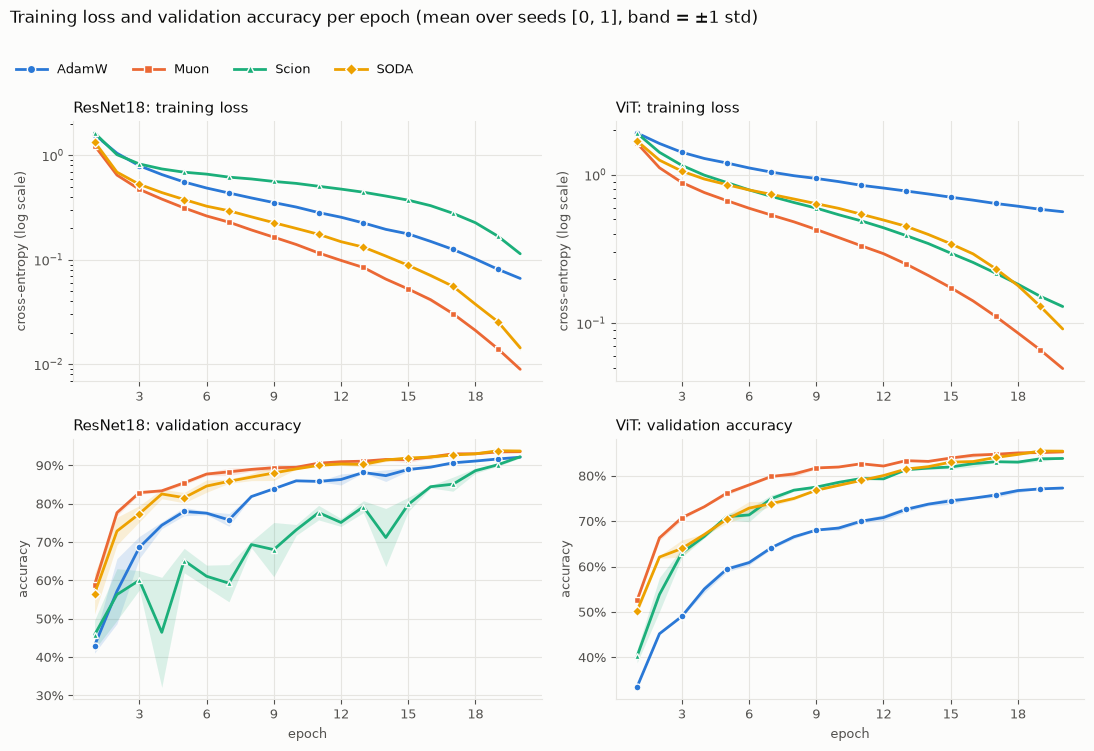

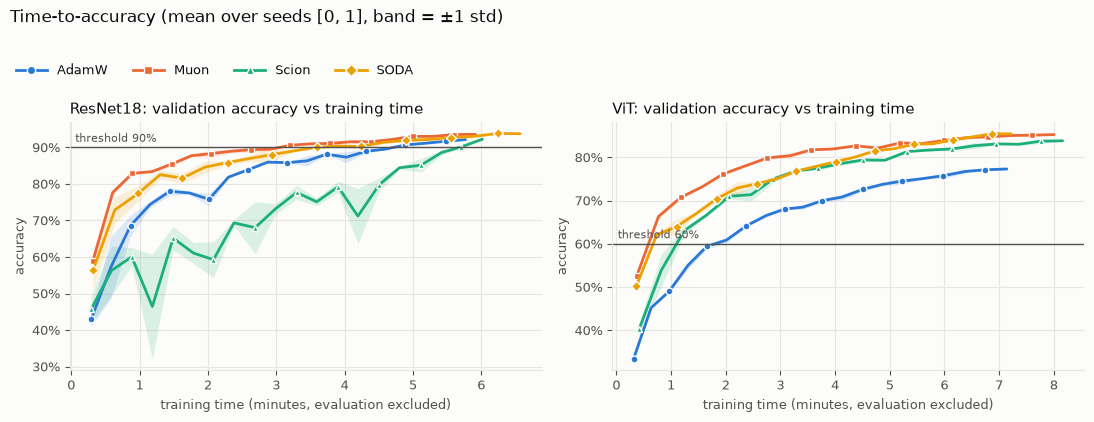

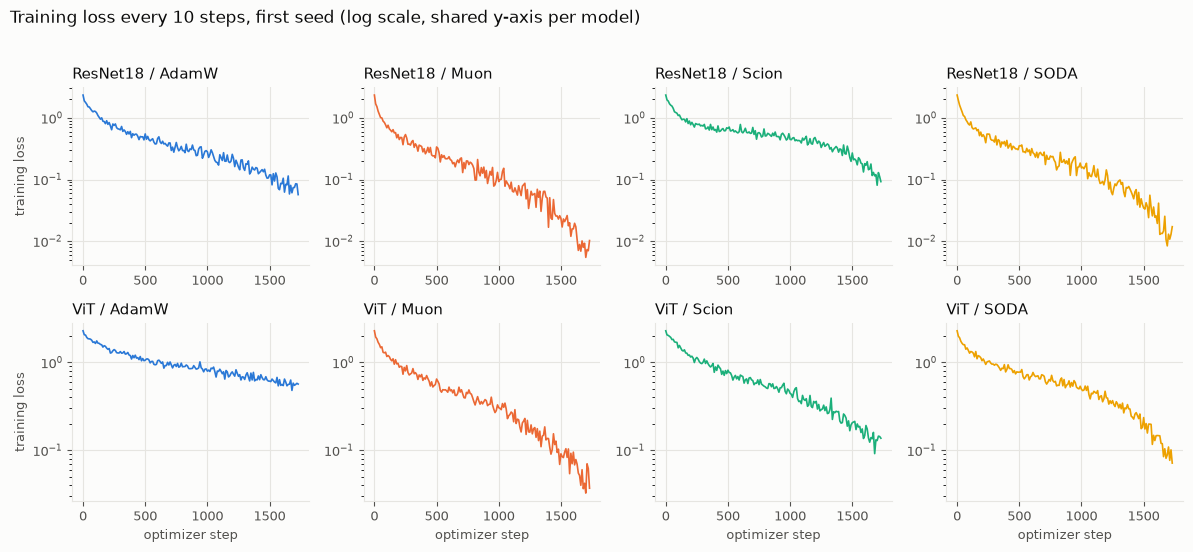

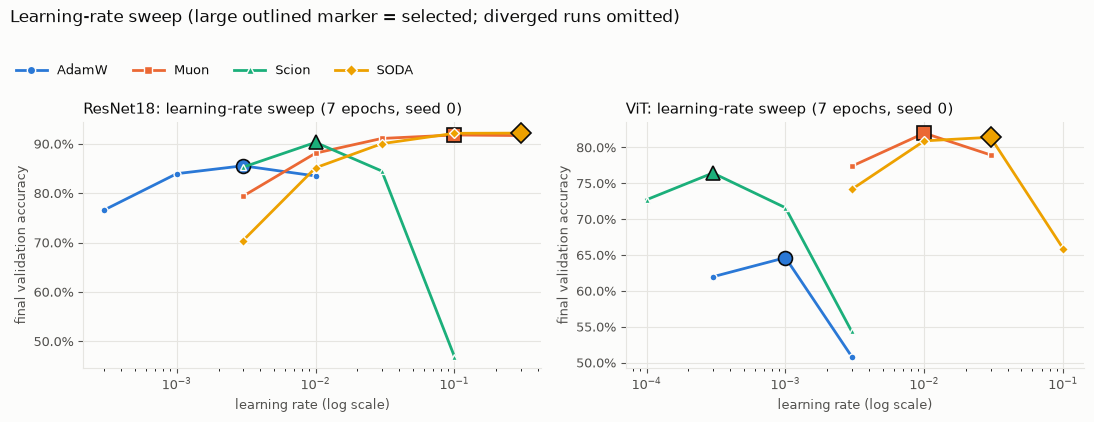

**ResNet18**: final runs, 20 epochs, mean over seeds [0, 1], band = ±1 std; accuracy of the last iterate; time to validation accuracy at epoch granularity, evaluation time excluded (primary threshold 90%)

| optimizer | lr | aux lr | completed | final val acc | test acc | best val acc | time to 80% | time to 85% | time to 90% | train time (min) | ms/step | peak GPU MB | mean SM clock MHz |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| AdamW | 0.003 | - | 2/2 | 92.13% ± 0.03 | 91.36% ± 0.13 | 92.13% ± 0.03 | 2.3 min, ep 8.0 | 2.9 min, ep 10.0 | 4.9 min, ep 17.0 | 5.8 | 198.9 | 1384 | 914 |
| Muon | 0.1 | 0.003 | 2/2 | 93.57% ± 0.21 | 93.16% ± 0.10 | 93.60% ± 0.24 | 0.9 min, ep 3.0 | 1.6 min, ep 5.5 | 3.0 min, ep 10.0 | 5.9 | 204.0 | 1342 | 1279 |
| Scion | 0.01 | - | 2/2 | 92.25% ± 0.33 | 92.53% ± 0.13 | 92.25% ± 0.33 | 4.5 min, ep 14.5 | 5.3 min, ep 17.5 | 5.8 min, ep 19.5 | 6.0 | 207.5 | 1342 | 1293 |
| SODA | 0.3 | 0.003 | 2/2 | 93.75% ± 0.03 | 93.44% ± 0.08 | 93.83% ± 0.05 | 1.3 min, ep 4.0 | 2.2 min, ep 6.5 | 3.8 min, ep 11.5 | 6.6 | 226.5 | 1385 | 1265 |

**ViT**: final runs, 20 epochs, mean over seeds [0, 1], band = ±1 std; accuracy of the last iterate; time to validation accuracy at epoch granularity, evaluation time excluded (primary threshold 60%)

| optimizer | lr | aux lr | completed | final val acc | test acc | best val acc | time to 50% | time to 55% | time to 60% | train time (min) | ms/step | peak GPU MB | mean SM clock MHz |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| AdamW | 0.001 | - | 2/2 | 77.31% ± 0.23 | 77.70% ± 0.09 | 77.31% ± 0.23 | 1.3 min, ep 4.0 | 1.6 min, ep 4.5 | 1.9 min, ep 5.5 | 7.1 | 246.2 | 2152 | 1042 |
| Muon | 0.01 | 0.001 | 2/2 | 85.27% ± 0.09 | 85.31% ± 0.50 | 85.27% ± 0.09 | 0.4 min, ep 1.0 | 0.8 min, ep 2.0 | 0.8 min, ep 2.0 | 8.0 | 276.1 | 2134 | 1052 |
| Scion | 0.0003 | - | 2/2 | 83.83% ± 0.01 | 83.92% ± 0.42 | 84.07% ± 0.23 | 0.8 min, ep 2.0 | 1.0 min, ep 2.5 | 1.2 min, ep 3.0 | 8.2 | 281.4 | 2134 | 1045 |
| SODA | 0.03 | 0.001 | 2/2 | 85.44% ± 0.14 | 85.51% ± 0.03 | 85.48% ± 0.10 | 0.6 min, ep 1.5 | 0.7 min, ep 2.0 | 0.7 min, ep 2.0 | 7.2 | 249.1 | 2152 | 1108 |

Figures saved in ./results/figures; tables saved as ./results/summary_<model>.csv


In [26]:
# Plot the results and produce a summary table.
# Everything is read from the run results of the previous cell (loaded from results files when
# they exist), so this cell can be re-run on its own after the sweep cell.
import csv
from IPython.display import Markdown, display
from matplotlib.ticker import MaxNLocator, PercentFormatter

# One fixed colour per optimizer (first four categorical slots of a colour-blind-validated
# palette, in their validated order) plus a marker per optimizer as a second encoding.
STYLE = {"AdamW": dict(color="#2a78d6", marker="o"), "Muon": dict(color="#eb6834", marker="s"),
         "Scion": dict(color="#1baf7a", marker="^"), "SODA": dict(color="#eda100", marker="D")}
SURFACE, TEXT, TEXT_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
FIG_DIR = os.path.join(RESULTS_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)


def style_axes(ax, title=None, xlabel=None, ylabel=None):
    ax.set_facecolor(SURFACE)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.grid(True, color=GRID, linewidth=0.8, linestyle="-")
    ax.set_axisbelow(True)
    ax.tick_params(colors=TEXT_2, labelsize=9)
    if title:
        ax.set_title(title, color=TEXT, fontsize=11, loc="left")
    if xlabel:
        ax.set_xlabel(xlabel, color=TEXT_2, fontsize=9)
    if ylabel:
        ax.set_ylabel(ylabel, color=TEXT_2, fontsize=9)


def new_figure(nrows, ncols, size):
    fig, axes = plt.subplots(nrows, ncols, figsize=size, squeeze=False, facecolor=SURFACE)
    return fig, axes


def finish(fig, name, title, legend=True):
    """Title on the first line, legend (one entry per optimizer) on its own line below it."""
    fig.text(0.01, 0.995, title, ha="left", va="top", color=TEXT, fontsize=12)
    top = 1 - 0.45 / fig.get_size_inches()[1]
    if legend:
        handles = [plt.Line2D([], [], linewidth=2, markersize=6, markeredgecolor=SURFACE, **STYLE[o], label=o)
                   for o in OPTIMIZER_ORDER]
        fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.005, top), ncol=len(handles),
                   frameon=False, fontsize=9, labelcolor=TEXT, handlelength=2.5)
        top -= 0.35 / fig.get_size_inches()[1]
    fig.tight_layout(rect=(0, 0, 1, top))
    fig.savefig(os.path.join(FIG_DIR, name), dpi=150, facecolor=SURFACE)
    plt.show()


def completed_runs(model_name, opt_name):
    return [r for (m, o, s), r in sorted(final_results.items()) if m == model_name and o == opt_name
            and r["status"] == "completed"]


def mean_std(runs, key):
    values = np.array([r["history"][key] for r in runs], dtype=float)
    return values.mean(axis=0), (values.std(axis=0) if len(runs) > 1 else None)


def plot_curve(ax, x, y, std, opt_name):
    st = STYLE[opt_name]
    ax.plot(x, y, color=st["color"], linewidth=2, solid_capstyle="round", marker=st["marker"],
            markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.0, markevery=max(1, len(x) // 10))
    if std is not None:
        ax.fill_between(x, y - std, y + std, color=st["color"], alpha=0.15, linewidth=0)


seed_note = f"mean over seeds {FINAL_SEEDS}, band = ±1 std" if len(FINAL_SEEDS) > 1 else f"seed {FINAL_SEEDS[0]}"
if not final_results:
    print("No final runs (RUN_FINAL_RUNS = False): only the learning-rate sweep is plotted.")
else:
    # Figure 1: training loss and validation accuracy per epoch.
    fig, axes = new_figure(2, len(MODELS), (11, 7.5))
    for j, model_name in enumerate(MODELS):
        for opt_name in OPTIMIZER_ORDER:
            runs = completed_runs(model_name, opt_name)
            if not runs:
                continue
            epochs = runs[0]["history"]["epoch"]
            plot_curve(axes[0, j], epochs, *mean_std(runs, "train_loss"), opt_name)
            plot_curve(axes[1, j], epochs, *mean_std(runs, "val_acc"), opt_name)
        axes[0, j].set_yscale("log")
        style_axes(axes[0, j], f"{model_name}: training loss", None, "cross-entropy (log scale)")
        style_axes(axes[1, j], f"{model_name}: validation accuracy", "epoch", "accuracy")
        axes[1, j].yaxis.set_major_formatter(PercentFormatter(1.0))
        for ax in axes[:, j]:
            ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    finish(fig, "loss_accuracy_per_epoch.png", f"Training loss and validation accuracy per epoch ({seed_note})")

    # Figure 2: validation accuracy against training wall-clock time (time-to-accuracy).
    fig, axes = new_figure(1, len(MODELS), (11, 4.2))
    for j, model_name in enumerate(MODELS):
        ax = axes[0, j]
        for opt_name in OPTIMIZER_ORDER:
            runs = completed_runs(model_name, opt_name)
            if runs:
                t, _ = mean_std(runs, "train_time")
                plot_curve(ax, t / 60, *mean_std(runs, "val_acc"), opt_name)
        threshold = tta_levels[model_name][-1]
        ax.axhline(threshold, color=TEXT_2, linewidth=1)
        ax.annotate(f"threshold {threshold:.0%}", xy=(0, threshold), xycoords=("axes fraction", "data"),
                    xytext=(4, 4), textcoords="offset points", color=TEXT_2, fontsize=8)
        style_axes(ax, f"{model_name}: validation accuracy vs training time", "training time (minutes, evaluation excluded)", "accuracy")
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    finish(fig, "accuracy_vs_time.png", f"Time-to-accuracy ({seed_note})")

    # Figure 3: training loss every LOG_EVERY steps, one panel per optimizer (stability).
    fig, axes = new_figure(len(MODELS), len(OPTIMIZER_ORDER), (12, 5.5))
    for i, model_name in enumerate(MODELS):
        for j, opt_name in enumerate(OPTIMIZER_ORDER):
            ax = axes[i, j]
            runs = completed_runs(model_name, opt_name)
            if runs:
                ax.plot(runs[0]["step_log"]["step"], runs[0]["step_log"]["loss"], color=STYLE[opt_name]["color"],
                        linewidth=1.2)
                ax.set_yscale("log")
            style_axes(ax, f"{model_name} / {opt_name}", "optimizer step" if i == len(MODELS) - 1 else None,
                       "training loss" if j == 0 else None)
        ymin = min(a.get_ylim()[0] for a in axes[i]); ymax = max(a.get_ylim()[1] for a in axes[i])
        for a in axes[i]:
            a.set_ylim(ymin, ymax)
    finish(fig, "training_loss_per_step.png",
           f"Training loss every {LOG_EVERY} steps, first seed (log scale, shared y-axis per model)", legend=False)

# Figure 4: learning-rate sweep.
fig, axes = new_figure(1, len(MODELS), (11, 4.2))
for j, model_name in enumerate(MODELS):
    ax = axes[0, j]
    for opt_name in OPTIMIZER_ORDER:
        runs = sweep_results[(model_name, opt_name)]
        lrs = [lr for lr, r in runs.items() if final_val_acc(r) > -math.inf]
        accs = [final_val_acc(runs[lr]) for lr in lrs]
        st = STYLE[opt_name]
        ax.plot(lrs, accs, color=st["color"], linewidth=2, marker=st["marker"], markersize=5,
                markeredgecolor=SURFACE, markeredgewidth=1.0)
        best = best_lr[(model_name, opt_name)]
        ax.plot([best], [final_val_acc(runs[best])], linestyle="none", marker=st["marker"], markersize=10,
                color=st["color"], markeredgecolor=TEXT, markeredgewidth=1.2)
    ax.set_xscale("log")
    style_axes(ax, f"{model_name}: learning-rate sweep ({sweep_epochs} epochs, seed {SWEEP_SEED})",
               "learning rate (log scale)", "final validation accuracy")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
finish(fig, "lr_sweep.png", "Learning-rate sweep (large outlined marker = selected; diverged runs omitted)")

# Summary tables, one per model (each model has its own time-to-accuracy thresholds), also
# saved as CSV files.
def fmt_mean_std(values, pct=True):
    if not values:
        return "-"
    m, s = float(np.mean(values)), float(np.std(values))
    return (f"{100 * m:.2f}%" + (f" ± {100 * s:.2f}" if len(values) > 1 else "")) if pct else f"{m:.1f}"


def summary_rows(model_name):
    rows = []
    for opt_name in OPTIMIZER_ORDER:
        runs_all = [r for (m, o, s), r in sorted(final_results.items()) if m == model_name and o == opt_name]
        runs = [r for r in runs_all if r["status"] == "completed"]
        row = {"optimizer": opt_name, "lr": f"{best_lr[(model_name, opt_name)]:g}",
               "aux lr": (f"{runs_all[0]['aux_lr']:g}" if runs_all and runs_all[0]["aux_lr"] else "-"),
               "completed": f"{len(runs)}/{len(runs_all)}",
               "final val acc": fmt_mean_std([r["history"]["val_acc"][-1] for r in runs]),
               "test acc": fmt_mean_std([r["test_acc"] for r in runs]),
               "best val acc": fmt_mean_std([max(r["history"]["val_acc"]) for r in runs])}
        for level in tta_levels[model_name]:
            hits = [h for h in (time_to_accuracy(r, level) for r in runs) if h is not None]
            note = "" if len(hits) == len(runs) else f" ({len(hits)}/{len(runs)} runs)"
            row[f"time to {level:.0%}"] = (f"{np.mean([h[0] for h in hits]) / 60:.1f} min, ep "
                                           f"{np.mean([h[1] for h in hits]):.1f}{note}" if hits else "not reached")
        row["train time (min)"] = fmt_mean_std([r["history"]["train_time"][-1] / 60 for r in runs], pct=False)
        row["ms/step"] = fmt_mean_std([1000 * r["time_per_step"] for r in runs], pct=False)
        peaks = [r["peak_memory_mb"] for r in runs if r["peak_memory_mb"] is not None]
        row["peak GPU MB"] = f"{max(peaks):.0f}" if peaks else "-"
        clocks = [s[1] for r in runs for s in r.get("gpu_status", {}).get("per_epoch", []) if s and s[1]]
        row["mean SM clock MHz"] = f"{np.mean(clocks):.0f}" if clocks else "-"
        rows.append(row)
    return rows


if final_results:
    for model_name in MODELS:
        rows = summary_rows(model_name)
        columns = list(rows[0])
        table = ["| " + " | ".join(columns) + " |", "|" + "---|" * len(columns)]
        table += ["| " + " | ".join(row[c] for c in columns) + " |" for row in rows]
        display(Markdown(f"**{model_name}**: final runs, {final_epochs} epochs, {seed_note}; accuracy of the "
                         f"last iterate; time to validation accuracy at epoch granularity, evaluation time "
                         f"excluded (primary threshold {tta_levels[model_name][-1]:.0%})\n\n" + "\n".join(table)))
        csv_path = os.path.join(RESULTS_DIR, f"summary_{model_name}.csv")
        with open(csv_path + ".tmp", "w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=columns)
            writer.writeheader()
            writer.writerows(rows)
        os.replace(csv_path + ".tmp", csv_path)
    print(f"Figures saved in {FIG_DIR}; tables saved as {RESULTS_DIR}/summary_<model>.csv")

## Discussion

**Setup in brief.** Both models were trained with the four optimizers on CIFAR-10. The data were split into 45,000 training images, 5,000 validation images held out from the training set, and the 10,000-image test set, which was used only once, at the end of each final run. Every run used batch size 512, 20 epochs and a linear learning-rate decay to zero; AdamW alone also had a 5% warmup. The learning rate of each (model, optimizer) pair was chosen by a sweep of 7-epoch runs, and every other hyperparameter was fixed at its reference value. The final runs used two seeds. For a given seed, all four optimizers started from identical weights and saw identical batches, which was checked through checksums stored with the results. None of the 48 runs (32 sweep runs and 16 final runs) diverged. Unless stated otherwise, the numbers below are means over the two seeds, with the two per-seed values in brackets; with two seeds, the "±" shown in the summary tables is half the gap between them. Before the experiments, the Muon, Scion and SODA implementations were checked against the reference code: on small models they produce bitwise-identical parameter updates.

#### 1. Final accuracy

| Model | Optimizer | LR | Validation acc. (%) | Test acc. (%) |
|---|---|---|---|---|
| ResNet-18 | AdamW | 3e-3 | 92.13 (92.10, 92.16) | 91.36 (91.23, 91.49) |
| ResNet-18 | Muon | 0.1 | 93.57 (93.36, 93.78) | 93.16 (93.06, 93.27) |
| ResNet-18 | Scion | 0.01 | 92.25 (92.58, 91.92) | 92.53 (92.66, 92.39) |
| ResNet-18 | SODA(Muon) | 0.3 | **93.75** (93.72, 93.78) | **93.44** (93.51, 93.36) |
| ViT | AdamW | 1e-3 | 77.31 (77.54, 77.08) | 77.70 (77.62, 77.79) |
| ViT | Muon | 0.01 | 85.27 (85.36, 85.18) | 85.31 (85.82, 84.81) |
| ViT | Scion | 3e-4 | 83.83 (83.82, 83.84) | 83.92 (84.33, 83.50) |
| ViT | SODA(Muon) | 0.03 | **85.44** (85.58, 85.30) | **85.51** (85.54, 85.48) |

- **The ranking is the same in both seeds and on both architectures:** Muon and SODA(Muon) come first, then Scion, then AdamW. On the ResNet, Scion and AdamW are close: Scion is ahead on the test set (92.53% vs 91.36%) but only marginally on validation (92.25% vs 92.13%).
- **The new optimizers gain much more on the Transformer than on the ResNet.** Muon is 1.4 validation points (1.8 test points) above AdamW on the ResNet, and 8.0 (7.6) points above it on the ViT. Muon and Scion give every hidden matrix an update of fixed size in the spectral or operator norm, whatever the scale of its gradient. This seems to help the ViT considerably over a short horizon, whereas BatchNorm already normalizes the ResNet's layers to a large extent.
- **SODA(Muon) vs Muon:** SODA is equal or slightly better in 7 of the 8 comparisons (validation/test × two seeds × two models). The mean gain is small, +0.18/+0.28 points (validation/test) on the ResNet and +0.17/+0.20 on the ViT, and of the same size as the seed-to-seed differences. It is therefore a consistent but not a significant improvement.
- **Validation and test accuracy agree within about one point** for every configuration, so selecting the learning rate on the held-out split did not overfit it.

#### 2. Convergence speed

Epochs needed to first reach a validation-accuracy threshold (seed 0, seed 1). The thresholds were fixed before the final runs; the ViT's 70% and 80% columns were added afterwards from the saved per-epoch logs, because the agreed primary threshold of 60% is reached within 2–3 epochs by three optimizers.

| Model | Threshold | AdamW | Muon | Scion | SODA(Muon) |
|---|---|---|---|---|---|
| ResNet-18 | 80% | 8, 8 | **3, 3** | 16, 13 | 4, 4 |
| ResNet-18 | 90% | 17, 17 | **11, 9** | 19, 20 | 12, 11 |
| ViT | 60% | 6, 5 | **2, 2** | 3, 3 | **2, 2** |
| ViT | 70% | 11, 12 | **3, 3** | 5, 5 | 6, 5 |
| ViT | 80% | not reached | **7, 8** | 13, 13 | 12, 13 |

- **Muon converges fastest in epochs on both models.** It needs about 40% fewer epochs than AdamW to reach 90% on the ResNet, in line with the result of Sato et al. (arXiv 2507.01598, §5) that Muon needs fewer steps than AdamW to reach 90% test accuracy with ResNet-18 on CIFAR-10. On the ViT it reaches 80% in 7–8 epochs, a level AdamW never reaches in 20 epochs.
- **SODA(Muon) starts slower than Muon but catches up.** It needs about one more epoch to reach 90% on the ResNet and about five more to reach 80% on the ViT, yet it ends equal or slightly higher. This matches the wrapper's update x<sub>k+1</sub> = z<sub>0</sub>/(k+2) + (1 − 1/(k+2)) x<sub>k</sub> + BaseUpdate<sub>k</sub>: the pull towards the initialization z<sub>0</sub> is strongest in the first steps (weight 1/2 at the first step) and fades like 1/k.
- **Scion is the slowest on the ResNet** because of the oscillations described in section 3. On the ViT it is much faster than AdamW and close to SODA(Muon): third at 60% and 80%, second at 70%.
- **Wall-clock time.** Muon, Scion and SODA run Newton–Schulz on every hidden matrix at every step (5 iterations in bf16), and SODA also copies and averages all the weights. Their epochs therefore cost more than AdamW's. Median time per epoch, in the only two subsets where all four optimizers ran at a similar GPU clock:

| Subset | AdamW | Muon | Scion | SODA(Muon) |
|---|---|---|---|---|
| ResNet-18, seed 0 (~900 MHz) | 17.7 s | 21.0 s (+19%) | 22.4 s (+27%) | 25.4 s (+44%) |
| ViT, seed 1 (~1.5–1.6 GHz) | 12.3 s | 16.4 s (+33%) | 17.1 s (+39%) | 17.3 s (+41%) |

  Even with this overhead, Muon is the fastest in wall-clock time to 90% on the ResNet: 3.8 min against 5.0 for AdamW, 5.0 for SODA and 7.1 for Scion (seed 0, all at the same clock).
- **Caveat on the time columns of the summary tables.** The two seeds were trained in two sessions with different laptop power settings. In the first session the GPU drew about 40–48 W and ran at or below 900 MHz; on the ViT the clock fell to a median of 450–620 MHz. In the second session, from the second run on, it drew about 67–70 W and ran at a median of 1.45–1.6 GHz. The ResNet AdamW run of seed 1 was still in the slow regime. The minutes and ms/step averaged over the two seeds therefore reflect the power mode more than the optimizer; the "mean SM clock" column shows the difference. Epochs or steps to a threshold are the hardware-independent comparison.

#### 3. Training stability and sensitivity to the learning rate

- **No run diverged**, in the sweep or in the final runs. The final accuracies of the two seeds differ by at most 0.66 validation points (Scion on the ResNet) and 1.0 test point (Muon on the ViT).
- **Scion on the ResNet is unstable in validation while the learning rate is high.** Its validation accuracy jumps from epoch to epoch, for example from 77.7% to 63.6% (epochs 13–14, seed 0) and from 62.6% to 32.1% (epochs 3–4, seed 1). It only settles once the learning rate has decayed: it reaches 90% at epochs 19 and 20 and ends at 92.25%. Its training loss, however, decreases smoothly (per-step loss figure), and it is the highest at the end (0.112 and 0.117). On the ViT, which has no BatchNorm, Scion is stable in both seeds. A plausible explanation, *not tested here*, involves the BatchNorm layers. The constrained Scion update moves every BatchNorm weight and bias vector by a fixed RMS amount (learning rate × radius) at every step and shrinks it by a factor (1 − lr), so the running statistics used in evaluation mode lag behind the rapidly changing layers. The airbench reference configuration, from which the radii and the learning-rate range come, freezes the BatchNorm weights and uses another network with batch size 2000; we kept them trainable for all optimizers. Freezing the BatchNorm weights, a smaller radius for them, or re-estimating the BatchNorm statistics before evaluation would be the natural experiments to test this.
- **Sensitivity to the learning rate** (7-epoch sweep, final validation accuracy):
  - The most sensitive configurations are Scion on the ResNet (90.3% at 0.01, 84.5% at 0.03, 46.9% at 0.1) and AdamW on the ViT (64.6% at 1e-3, 50.9% at 3e-3).
  - Muon and SODA on the ResNet are flat at the top of their range (Muon 91.8% at 0.1 and 91.7% at 0.3; SODA 92.1% and 92.2%), so the selected SODA learning rate (0.3, at the edge of the tried values after two extensions of the grid) is not critical.
  - The best Muon learning rate on the ResNet (0.1) is much larger than the README default (0.02) and than the grid of Sato et al. (at most 0.01, with 100 epochs). Conv kernels are flattened to (out, 9·in) matrices, and with the shape factor max(1, rows/cols)<sup>1/2</sup> = 1 the orthogonalized update has entries of RMS size 1/√(9·in), so a larger learning rate is needed. The airbench Muon configuration for a CIFAR CNN likewise uses lr 0.24. Its product with Muon's weight decay (0.1 × 0.01 = 10<sup>-3</sup>) is far from the stability boundary lr·wd ≤ 1 of Sato et al. (Prop. 3.1–3.2).

#### 4. Generalization and implicit regularization

- **SODA(Muon) has a higher final training loss than Muon in both seeds,** yet equal or better validation and test accuracy:

  | | SODA(Muon) | Muon |
  |---|---|---|
  | ResNet, final training loss | 0.015 / 0.014 | 0.009 / 0.009 |
  | ViT, final training loss | 0.093 / 0.090 | 0.050 / 0.049 |
  | ViT, accuracy on training batches | about 97% | about 98.5% |

  The averaging towards the initialization therefore acts as a regularizer, as the SODA paper intends. The paper focuses on single-epoch training and warns that multi-epoch training may need an extra regularization-strength hyperparameter (SODA, §1 "Limitations"). Over 20 epochs of CIFAR-10 we see no sign of harmful over- or under-regularization without such a parameter. However, Muon's weight decay (0.01) was fixed rather than tuned, so the paper's stronger claim, that SODA(Muon) beats Muon with *tuned* weight decay, is not tested here.
- **AdamW underfits the ViT.** Its final training loss is still 0.56 and its accuracy on training batches about 80%, only about 3 points above its validation accuracy, while the other optimizers fit the training data far better (gaps of 12–13 points). Twenty epochs are short for a ViT trained from scratch with AdamW. In addition, only AdamW's learning rate was tuned (its optimum, 1e-3, lies inside the grid); betas, weight decay and warmup were fixed. The baseline may therefore be under-tuned, as Keller Jordan's Muon blog warns.
- **On the ResNet all optimizers fit the training data well.** Accuracy on training batches is 96–99.8%, and the train-validation gap is between about 4 points (Scion) and 6 points (Muon, SODA, AdamW).

#### 5. Memory

Peak GPU memory is dominated by the activations: 1,342–1,385 MB for the ResNet and 2,134–2,152 MB for the ViT, well within 6 GB. The differences follow the optimizer states:
- AdamW stores two buffers per parameter;
- Muon stores one buffer for the hidden matrices and two for the auxiliary AdamW parameters;
- Scion stores one buffer;
- SODA(Muon) adds z<sub>0</sub> and a temporary copy of the weights at every step.

Accordingly, Muon and Scion have the lowest peaks (1,342 / 2,134 MB), and AdamW and SODA(Muon) the highest (1,383–1,385 / 2,152 MB).

#### 6. Limitations

- **Statistics:** only two seeds for the final runs, and one seed for a short (7-epoch) learning-rate sweep. Differences below about one point, in particular SODA vs Muon, are not statistically established.
- **Tuning:** only the learning rate was tuned. Momentum, weight decay, the Scion radii (taken from configurations for other networks and batch sizes) and the AdamW warmup were fixed.
- **Training length:** 20 epochs is a short horizon, especially for AdamW on the ViT; the ranking could change with longer training.
- **Timing:** wall-clock measurements are confounded by the laptop's power mode, which changed between sessions (about 45 W vs about 70 W). Epoch counts are the reliable speed measure. The sweep runs, apart from its last two points, have no GPU log.
- **Threshold choice:** the ViT's primary threshold (60%, fixed by the rule chosen before the final runs) saturates within 2–3 epochs, so higher thresholds were added in the analysis.

#### 7. Conclusion

On both architectures, the matrix-aware optimizers outperform the AdamW baseline at the same epoch budget and with only the learning rate tuned. Muon gives the fastest convergence in epochs and in wall-clock time, despite a cost per epoch 19% (ResNet) to 33% (ViT) higher than AdamW's. SODA(Muon) needs no additional hyperparameter, starts more slowly, and ends with the best or equal-best accuracy and a larger train-test margin, although its advantage over Muon is within the seed-to-seed variation. Scion is competitive on the ViT but unstable on the BatchNorm ResNet in this configuration. The gains are largest on the Transformer (+8 points over AdamW), where AdamW also underfits within 20 epochs.

## Reflection on AI-assisted coding

*Write your answer here.*
